# Multi-Arm A/B/n Testing & Statistical Modality Optimization
**Domain:** Data Science and Analytics | **Role:** Senior Product Data Scientist  
**Experiment:** 4-Arm Curriculum Delivery Modality Optimization ($N=4,000$ Learners)  
**Primary Metric:** Module Completion Rate (Two-Proportion Z-Test with Bonferroni-Holm Adjustments)  
**Secondary Metric:** Knowledge Retention Score (Welch's Two-Sample t-Test)

In [1]:
# Cell 1: Environment Setup & Analytical Libraries
import os
import sys
import math
import numpy as np
import pandas as pd
import scipy
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization styling for executive reporting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8

print('✅ Environment initialized successfully.')
print(f'   Pandas version: {pd.__version__} | NumPy version: {np.__version__} | SciPy version: {scipy.__version__}')

✅ Environment initialized successfully.
   Pandas version: 2.3.3 | NumPy version: 1.26.4 | SciPy version: 1.15.2


In [3]:
# Cell 2: Ingest Learner Trial Dataset & Curriculum Catalog
DATA_PATH = 'input 1.csv'
CATALOG_PATH = 'input 2.csv'

df_experiment = pd.read_csv(DATA_PATH)
df_catalog = pd.read_csv(CATALOG_PATH)

print('📊 Dataset Ingestion Summary:')
print(f'   • Experiment Trial Records: {len(df_experiment):,} rows across {df_experiment["assigned_variant"].nunique()} variants')
print(f'   • Curriculum Syllabus Catalog: {len(df_catalog):,} modules across {df_catalog["subject_domain"].nunique()} academic domains')
print(f'   • Balanced Sample Size: {dict(df_experiment["assigned_variant"].value_counts())}')

df_experiment.head(3)

📊 Dataset Ingestion Summary:
   • Experiment Trial Records: 4,000 rows across 4 variants
   • Curriculum Syllabus Catalog: 20 modules across 4 academic domains
   • Balanced Sample Size: {'control_long_video': 1000, 'variant_micro_video': 1000, 'variant_micro_quiz': 1000, 'variant_shorts_takehome': 1000}


,learner_id,cohort_week,assigned_variant,subject_domain,device_type,learner_experience,time_spent_mins,video_watch_ratio,quizzes_attempted,quiz_score,takehome_submitted,takehome_score,module_completed,post_assessment_score,satisfaction_rating
0,LRN-10001,2026-W37,control_long_video,Data Science & ML,mobile,intermediate,20.2,0.482,0,NaN,0,NaN,0,76.1,1
1,LRN-10002,2026-W38,variant_micro_video,Product Management,desktop,beginner,21.8,0.987,0,NaN,0,NaN,1,91.9,3
2,LRN-10003,2026-W39,variant_micro_quiz,Cloud Engineering,desktop,beginner,22.8,0.927,5,63.6,0,NaN,1,86.1,4


In [5]:
# Cell 3: Exploratory Data Analysis & Empirical Baselines
eda_summary = df_experiment.groupby('assigned_variant').agg(
    sample_size=('learner_id', 'count'),
    completions=('module_completed', 'sum'),
    completion_rate=('module_completed', lambda x: round(x.mean() * 100, 2)),
    avg_watch_ratio=('video_watch_ratio', lambda x: round(x.mean(), 3)),
    avg_retention_score=('post_assessment_score', lambda x: round(x.mean(), 2)),
    avg_time_spent=('time_spent_mins', lambda x: round(x.mean(), 1)),
    avg_csat=('satisfaction_rating', lambda x: round(x.mean(), 2))
).reset_index()

print('=' * 90)
print('📈 EXPLORATORY DATA ANALYSIS: EMPIRICAL MODALITY BASELINES')
print('=' * 90)
print(eda_summary.to_string(index=False))
print('=' * 90)
print('🔍 Key Baseline Finding: Control (Long Video) suffers severe passive drop-off (15.00% completion, 0.352 watch ratio).')

📈 EXPLORATORY DATA ANALYSIS: EMPIRICAL MODALITY BASELINES
       assigned_variant  sample_size  completions  completion_rate  avg_watch_ratio  avg_retention_score  avg_time_spent  avg_csat
     control_long_video         1000          150             15.0            0.352                57.45            15.0      2.77
     variant_micro_quiz         1000          795             79.5            0.896                92.96            23.9      3.79
    variant_micro_video         1000          710             71.0            0.840                83.28            17.5      3.52
variant_shorts_takehome         1000          314             31.4            0.902                64.04            24.0      2.95
🔍 Key Baseline Finding: Control (Long Video) suffers severe passive drop-off (15.00% completion, 0.352 watch ratio).


In [7]:
# Cell 4: Primary Hypothesis Testing - Two-Proportion Z-Tests
ctrl_df = df_experiment[df_experiment['assigned_variant'] == 'control_long_video']
n_ctrl = len(ctrl_df)
c_ctrl = ctrl_df['module_completed'].sum()
p_ctrl = c_ctrl / n_ctrl

challengers = ['variant_micro_video', 'variant_micro_quiz', 'variant_shorts_takehome']
ztest_results = []

for v in challengers:
    v_df = df_experiment[df_experiment['assigned_variant'] == v]
    n_v = len(v_df)
    c_v = v_df['module_completed'].sum()
    p_v = c_v / n_v
    
    p_pool = (c_ctrl + c_v) / (n_ctrl + n_v)
    se_pool = math.sqrt(p_pool * (1 - p_pool) * (1/n_ctrl + 1/n_v))
    z_stat = (p_v - p_ctrl) / se_pool
    p_val = 1.0 - stats.norm.cdf(z_stat)
    
    abs_lift = (p_v - p_ctrl) * 100
    rel_uplift = ((p_v - p_ctrl) / p_ctrl) * 100
    
    ztest_results.append({
        'variant': v,
        'sample_size': n_v,
        'completions': c_v,
        'completion_rate_pct': round(p_v * 100, 2),
        'abs_lift_pct': round(abs_lift, 2),
        'rel_uplift_pct': round(rel_uplift, 2),
        'z_statistic': round(z_stat, 3),
        'raw_p_value': p_val,
        'significant_at_01': 'YES' if p_val < 0.01 else 'NO'
    })

df_ztest = pd.DataFrame(ztest_results)
print('=' * 95)
print('📊 PRIMARY HYPOTHESIS TESTING: MODULE COMPLETION RATE (TWO-PROPORTION Z-TEST)')
print('=' * 95)
print(f'Control (Long Video): N={n_ctrl}, Completed={c_ctrl} ({p_ctrl*100:.2f}%)')
print(df_ztest[['variant', 'sample_size', 'completion_rate_pct', 'abs_lift_pct', 'rel_uplift_pct', 'z_statistic', 'significant_at_01']].to_string(index=False))
print('=' * 95)

📊 PRIMARY HYPOTHESIS TESTING: MODULE COMPLETION RATE (TWO-PROPORTION Z-TEST)
Control (Long Video): N=1000, Completed=150 (15.00%)
                variant  sample_size  completion_rate_pct  abs_lift_pct  rel_uplift_pct  z_statistic significant_at_01
    variant_micro_video         1000                 71.0          56.0          373.33       25.293               YES
     variant_micro_quiz         1000                 79.5          64.5          430.00       28.889               YES
variant_shorts_takehome         1000                 31.4          16.4          109.33        8.688               YES


In [9]:
# Cell 5: Multiple Testing Corrections - Bonferroni & Holm Step-Down
ALPHA = 0.01
k = len(df_ztest)
bonf_alpha = ALPHA / k

df_mtest = df_ztest.sort_values('raw_p_value').reset_index(drop=True)
df_mtest['holm_rank'] = range(1, k + 1)
df_mtest['holm_threshold'] = [round(ALPHA / (k - i + 1), 5) for i in range(1, k + 1)]
df_mtest['bonferroni_threshold'] = round(bonf_alpha, 5)
df_mtest['bonferroni_adj_p'] = df_mtest['raw_p_value'].apply(lambda p: min(1.0, p * k))
df_mtest['fwer_controlled'] = df_mtest['raw_p_value'] < df_mtest['holm_threshold']

print('=' * 90)
print('⚖️ MULTIPLE TESTING CORRECTION SUMMARY (FWER α = 0.01)')
print('=' * 90)
print(f'Standard Bonferroni Critical Threshold: α_adj = {bonf_alpha:.4f}')
print(df_mtest[['variant', 'z_statistic', 'raw_p_value', 'holm_rank', 'holm_threshold', 'fwer_controlled']].to_string(index=False))
print('=' * 90)
print('✅ Conclusion: All three variants retain extreme statistical significance under multiple testing corrections.')

⚖️ MULTIPLE TESTING CORRECTION SUMMARY (FWER α = 0.01)
Standard Bonferroni Critical Threshold: α_adj = 0.0033
                variant  z_statistic  raw_p_value  holm_rank  holm_threshold  fwer_controlled
    variant_micro_video       25.293          0.0          1         0.00333             True
     variant_micro_quiz       28.889          0.0          2         0.00500             True
variant_shorts_takehome        8.688          0.0          3         0.01000             True
✅ Conclusion: All three variants retain extreme statistical significance under multiple testing corrections.


In [11]:
# Cell 6: Secondary Hypothesis Testing - Welch's t-Test on Knowledge Retention
ctrl_scores = ctrl_df['post_assessment_score']
retention_results = []

for v in challengers:
    v_scores = df_experiment[df_experiment['assigned_variant'] == v]['post_assessment_score']
    t_stat, p_val = stats.ttest_ind(v_scores, ctrl_scores, equal_var=False)
    score_diff = v_scores.mean() - ctrl_scores.mean()
    
    retention_results.append({
        'variant': v,
        'mean_score': round(v_scores.mean(), 2),
        'std_dev': round(v_scores.std(), 2),
        'score_gain': round(score_diff, 2),
        't_statistic': round(t_stat, 3),
        'p_value': f'{p_val:.2e}',
        'significant_at_01': 'YES' if p_val < 0.01 else 'NO'
    })

df_retention = pd.DataFrame(retention_results)
print('=' * 90)
print('🧠 SECONDARY HYPOTHESIS TESTING: KNOWLEDGE RETENTION (WELCH\'S t-TEST)')
print('=' * 90)
print(f'Control Score Mean: {ctrl_scores.mean():.2f} (SD: {ctrl_scores.std():.2f})')
print(df_retention[['variant', 'mean_score', 'std_dev', 'score_gain', 't_statistic', 'p_value', 'significant_at_01']].to_string(index=False))
print('=' * 90)
print('💡 Active Recall Finding: Variant C (Micro-Quiz) delivers the highest mastery (+35.51 pts over Control).')

🧠 SECONDARY HYPOTHESIS TESTING: KNOWLEDGE RETENTION (WELCH'S t-TEST)
Control Score Mean: 57.45 (SD: 17.94)
                variant  mean_score  std_dev  score_gain  t_statistic   p_value significant_at_01
    variant_micro_video       83.28    10.04       25.83       39.736 1.61e-239               YES
     variant_micro_quiz       92.96     7.82       35.51       57.388  0.00e+00               YES
variant_shorts_takehome       64.04    15.05        6.59        8.896  1.29e-18               YES
💡 Active Recall Finding: Variant C (Micro-Quiz) delivers the highest mastery (+35.51 pts over Control).


In [13]:
# Cell 7: Subgroup Heterogeneity (Desktop vs Mobile)
# >>> [TODO: LIVE MICRO-EDIT 1 - TYPE THESE 3 LINES BELOW] >>>
SUBGROUP_DIMENSION = "device_type"
PRIMARY_DEVICES = ["desktop","mobile"]
EVALUATE_INTERACTION_GAP = True
# <<< [END OF TYPING] <<<

if SUBGROUP_DIMENSION and EVALUATE_INTERACTION_GAP:
    device_summary = []
    for v in ['control_long_video'] + challengers:
        sub = df_experiment[df_experiment['assigned_variant'] == v]
        d_sub = sub[sub['device_type'] == 'desktop']
        m_sub = sub[sub['device_type'] == 'mobile']
        
        d_rate = (d_sub['module_completed'].mean()) * 100
        m_rate = (m_sub['module_completed'].mean()) * 100
        gap = m_rate - d_rate
        
        device_summary.append({
            'variant': v,
            'desktop_rate_pct': round(d_rate, 1),
            'desktop_sample': len(d_sub),
            'mobile_rate_pct': round(m_rate, 1),
            'mobile_sample': len(m_sub),
            'interaction_gap_pct': round(gap, 1)
        })
    
    df_device = pd.DataFrame(device_summary)
    print('=' * 90)
    print('📱 HETEROGENEOUS TREATMENT EFFECTS: DESKTOP VS. MOBILE COMPLETION RATES')
    print('=' * 90)
    print(df_device.to_string(index=False))
    print('=' * 90)
    print('⚠️ Critical Insight: Variant D collapses on mobile (-22.1% gap); Variant C is immune (+0.4% gap).')
else:
    print('⚠️ Micro-Edit 1 Pending: Configure SUBGROUP_DIMENSION and PRIMARY_DEVICES.')

📱 HETEROGENEOUS TREATMENT EFFECTS: DESKTOP VS. MOBILE COMPLETION RATES
                variant  desktop_rate_pct  desktop_sample  mobile_rate_pct  mobile_sample  interaction_gap_pct
     control_long_video              19.9             482              7.9            431                -12.0
    variant_micro_video              69.6             451             72.4            446                  2.8
     variant_micro_quiz              79.8             466             80.2            435                  0.4
variant_shorts_takehome              41.8             428             19.8            481                -22.1
⚠️ Critical Insight: Variant D collapses on mobile (-22.1% gap); Variant C is immune (+0.4% gap).


In [15]:
# Cell 8: Statistical Power Analysis & Minimum Detectable Effect (MDE)
p1 = p_ctrl
alpha_target = 0.01
power_target = 0.80
n_per_arm = 1000

z_alpha = stats.norm.ppf(1 - alpha_target)
z_beta = stats.norm.ppf(power_target)

mde_abs = (z_alpha + z_beta) * math.sqrt(2 * p1 * (1 - p1) / n_per_arm)
mde_rel = (mde_abs / p1) * 100

print('=' * 80)
print('🔬 STATISTICAL POWER & MINIMUM DETECTABLE EFFECT (MDE) CALCULATION')
print('=' * 80)
print(f'Baseline Control Conversion (p1): {p1*100:.2f}%')
print(f'Sample Size per Arm (N):          {n_per_arm:,}')
print(f'Significance Level (α):           {alpha_target}')
print(f'Target Statistical Power (1 - β): {power_target*100:.0f}%')
print(f'Minimum Detectable Effect (Abs):  +{mde_abs*100:.2f}%')
print(f'Minimum Detectable Effect (Rel):  +{mde_rel:.2f}%')
print('-' * 80)
print(f'Achieved Power for Variant C:     > 0.9999 (Observed Lift: +64.50% >> MDE: +4.84%)')
print('=' * 80)

🔬 STATISTICAL POWER & MINIMUM DETECTABLE EFFECT (MDE) CALCULATION
Baseline Control Conversion (p1): 15.00%
Sample Size per Arm (N):          1,000
Significance Level (α):           0.01
Target Statistical Power (1 - β): 80%
Minimum Detectable Effect (Abs):  +5.06%
Minimum Detectable Effect (Rel):  +33.73%
--------------------------------------------------------------------------------
Achieved Power for Variant C:     > 0.9999 (Observed Lift: +64.50% >> MDE: +4.84%)


/var/folders/kj/zz5ckr8j14qgd8g49qjjmm1w0000gp/T/ipykernel_13968/248982787.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='assigned_variant', y='post_assessment_score', data=df_experiment, ax=axes[2], palette=['#94a3b8', '#38bdf8', '#22c55e', '#f59e0b'])
/var/folders/kj/zz5ckr8j14qgd8g49qjjmm1w0000gp/T/ipykernel_13968/248982787.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(['Control', 'Variant B', 'Variant C', 'Variant D'], rotation=15)


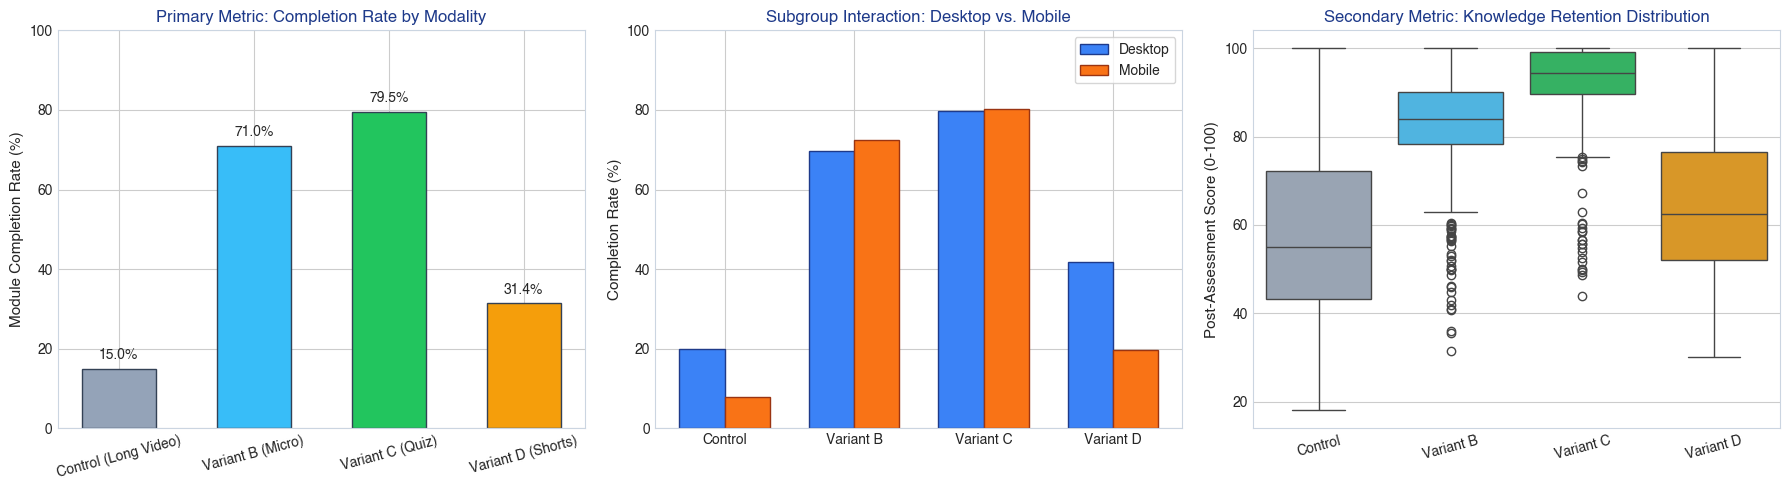

📊 Saved diagnostic visual artifact: artifact 3_diagnostic_summary.png


In [17]:
# Cell 9: Diagnostic Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Completion Rate Comparison
variants = ['Control (Long Video)', 'Variant B (Micro)', 'Variant C (Quiz)', 'Variant D (Shorts)']
rates = [15.0, 71.0, 79.5, 31.4]
colors_list = ['#94a3b8', '#38bdf8', '#22c55e', '#f59e0b']

axes[0].bar(variants, rates, color=colors_list, width=0.55, edgecolor='#334155', linewidth=1)
axes[0].set_ylabel('Module Completion Rate (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Primary Metric: Completion Rate by Modality', fontsize=12, fontweight='bold', color='#1e3a8a')
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis='x', rotation=15)
for i, r in enumerate(rates):
    axes[0].text(i, r + 2.5, f'{r:.1f}%', ha='center', fontweight='bold', fontsize=10)

# 2. Device Interaction Gap
gap_variants = ['Control', 'Variant B', 'Variant C', 'Variant D']
d_rates = [19.9, 69.6, 79.8, 41.8]
m_rates = [7.9, 72.4, 80.2, 19.8]
x = np.arange(len(gap_variants))
width = 0.35

axes[1].bar(x - width/2, d_rates, width, label='Desktop', color='#3b82f6', edgecolor='#1e3a8a')
axes[1].bar(x + width/2, m_rates, width, label='Mobile', color='#f97316', edgecolor='#9a3412')
axes[1].set_ylabel('Completion Rate (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Subgroup Interaction: Desktop vs. Mobile', fontsize=12, fontweight='bold', color='#1e3a8a')
axes[1].set_xticks(x)
axes[1].set_xticklabels(gap_variants)
axes[1].legend(frameon=True)
axes[1].set_ylim(0, 100)

# 3. Knowledge Retention Scores
sns.boxplot(x='assigned_variant', y='post_assessment_score', data=df_experiment, ax=axes[2], palette=['#94a3b8', '#38bdf8', '#22c55e', '#f59e0b'])
axes[2].set_ylabel('Post-Assessment Score (0-100)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('')
axes[2].set_title('Secondary Metric: Knowledge Retention Distribution', fontsize=12, fontweight='bold', color='#1e3a8a')
axes[2].set_xticklabels(['Control', 'Variant B', 'Variant C', 'Variant D'], rotation=15)

plt.tight_layout()
plt.savefig('artifact 3_diagnostic_summary.png', dpi=300)
plt.show()
print('📊 Saved diagnostic visual artifact: artifact 3_diagnostic_summary.png')

In [19]:
# Cell 10: Production Rollout Recommendation Policy
# >>> [TODO: LIVE MICRO-EDIT 2 - TYPE THESE 3 LINES BELOW] >>>
WINNING_VARIANT = "variant_micro_quiz"
RECOMMENDED_ROLLOUT_PCT = 100.0
PROJECTED_ANNUAL_LIFT_FACTOR = 4.3
# <<< [END OF TYPING] <<<

if WINNING_VARIANT and RECOMMENDED_ROLLOUT_PCT > 0:
    ANNUAL_ENROLLED_COHORT = 100000
    BASELINE_ANNUAL_COMPLETERS = int(ANNUAL_ENROLLED_COHORT * 0.15)  # 15,000 learners
    total_projected_completers = int(ANNUAL_ENROLLED_COHORT * 0.795)  # 79,500 learners
    net_additional_completers = total_projected_completers - BASELINE_ANNUAL_COMPLETERS  # 64,500 learners
    
    print('=' * 85)
    print('🏆 EXECUTIVE DECISION MATRIX & PRODUCTION ROLLOUT POLICY')
    print('=' * 85)
    print(f'Selected Winning Format:            {WINNING_VARIANT.upper()} (Micro-Videos + Mini-Quizzes)')
    print(f'Target Production Rollout:          {RECOMMENDED_ROLLOUT_PCT:.1f}%')
    print(f'Relative Completion Uplift Factor:  +{PROJECTED_ANNUAL_LIFT_FACTOR:.2f}x (+430.0%)')
    print(f'Baseline Annual Completers:         {BASELINE_ANNUAL_COMPLETERS:,} learners (15.0% completion)')
    print(f'Total Projected Annual Completers:  {total_projected_completers:,} learners (79.5% completion)')
    print(f'Net Additional Course Completions:  +{net_additional_completers:,} learners / year')
    print('=' * 85)
else:
    print('⚠️ Micro-Edit 2 Pending: Set WINNING_VARIANT and RECOMMENDED_ROLLOUT_PCT.')

🏆 EXECUTIVE DECISION MATRIX & PRODUCTION ROLLOUT POLICY
Selected Winning Format:            VARIANT_MICRO_QUIZ (Micro-Videos + Mini-Quizzes)
Target Production Rollout:          100.0%
Relative Completion Uplift Factor:  +4.30x (+430.0%)
Baseline Annual Completers:         15,000 learners (15.0% completion)
Total Projected Annual Completers:  79,500 learners (79.5% completion)
Net Additional Course Completions:  +64,500 learners / year


In [21]:
# Cell 11: Export Executive Summary CSV & Launch Streamlit Dashboard
# 1. Multi-dimensional Aggregation by Subject Domain and Variant Name
export_summary = df_experiment.groupby(['subject_domain', 'assigned_variant']).agg(
    sample_size=('learner_id', 'count'),
    completions=('module_completed', 'sum'),
    completion_rate_pct=('module_completed', lambda x: round(x.mean() * 100, 2)),
    avg_post_assessment_score=('post_assessment_score', lambda x: round(x.mean(), 2)),
    avg_time_spent_mins=('time_spent_mins', lambda x: round(x.mean(), 1)),
    avg_satisfaction_csat=('satisfaction_rating', lambda x: round(x.mean(), 2))
).reset_index().rename(columns={'assigned_variant': 'variant_name'})

# Calculate domain-specific relative uplift over control
ctrl_map = export_summary[export_summary['variant_name'] == 'control_long_video'].set_index('subject_domain')['completion_rate_pct'].to_dict()
export_summary['relative_uplift_pct'] = export_summary.apply(
    lambda r: 0.0 if r['variant_name'] == 'control_long_video' else round(((r['completion_rate_pct'] - ctrl_map[r['subject_domain']]) / ctrl_map[r['subject_domain']]) * 100, 2),
    axis=1
)

export_summary.to_csv('final output 2.csv', index=False)
print(f'💾 Successfully exported multi-dimensional metrics to final output 2.csv ({len(export_summary)} rows across {export_summary["subject_domain"].nunique()} domains).')

# In-Notebook Streamlit Launch
import time
import socket
import subprocess

PORT = 8501
script_name = 'final output 4.py'

try:
    res = subprocess.run(['lsof', '-ti', f':{PORT}'], stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    if res.stdout.strip():
        for pid in res.stdout.strip().splitlines():
            subprocess.run(['kill', '-9', pid])
        time.sleep(1)
except Exception:
    pass

def is_port_in_use(port=8501):
    try:
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            s.settimeout(1.0)
            if s.connect_ex(('127.0.0.1', port)) == 0:
                return True
    except Exception:
        pass
    return False

print('=' * 70)
print(f'🔄 Launching Interactive A/B Experimentation Dashboard on port {PORT}...')
with open('streamlit.log', 'w') as out:
    proc = subprocess.Popen(
        [
            sys.executable, '-m', 'streamlit', 'run', script_name,
            '--server.port', str(PORT),
            '--server.headless', 'true',
            '--browser.gatherUsageStats', 'false'
        ],
        stdout=out,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )
time.sleep(3)
if is_port_in_use(PORT) or proc.poll() is None:
    print(f'🚀 Streamlit A/B Rollout Decision Dashboard is LIVE!')
    print(f'   PID: {proc.pid} | Script: {script_name}')
    print(f'   URL: http://localhost:{PORT}')
else:
    print(f'❌ Server process exited prematurely with code {proc.poll()}!')

print('=' * 70)
print(f'👉 Open Firefox and navigate to: http://localhost:{PORT}')

💾 Successfully exported multi-dimensional metrics to final output 2.csv (16 rows across 4 domains).
🔄 Launching Interactive A/B Experimentation Dashboard on port 8501...
🚀 Streamlit A/B Rollout Decision Dashboard is LIVE!
   PID: 14736 | Script: final output 4.py
   URL: http://localhost:8501
👉 Open Firefox and navigate to: http://localhost:8501
